In [1]:
# Laboratorio 03 - Métodos Supervisados: Regresión y benchmarking
# Autores: Brandon Brenes Umaña
#          Sebastián Alpízar Porras
#          Darío Gutiérrez Jiménez
# Fecha: Octubre 2026

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mvc import DataFrameModel, DataFrameView, DataFrameController

warnings.filterwarnings("ignore")
CRITERIO = "RMSE"   # índice para escoger el mejor modelo de cada algoritmo (menor es mejor)
CARPETA = "figuras/regresion"
INFORME = "../Informes/LAB3/figuras"   # las figuras también se copian al informe
os.makedirs(CARPETA, exist_ok=True)

def guardar(nombre):
    plt.savefig(f"{CARPETA}/{nombre}", dpi=150, bbox_inches="tight")
    if os.path.isdir(os.path.dirname(INFORME)):
        os.makedirs(INFORME, exist_ok=True)
        plt.savefig(f"{INFORME}/{nombre}", dpi=150, bbox_inches="tight")

# Crimen violento en comunidades de EE. UU. (Communities and Crime, `USCrime.csv`)

1994 comunidades de EE. UU. descritas por 100 variables socioeconómicas, demográficas y policiales (censo de 1990 y encuesta LEMAS), y la variable a predecir `ViolentCrimesPerPop`: crímenes violentos por cada 100 000 habitantes. Todas las variables vienen **normalizadas al intervalo [0, 1]** por los autores del conjunto de datos. Las columnas `state` (código del estado) y `fold` (partición sugerida por los autores) no son predictoras, así que se excluyen. Es el mismo conjunto que usamos en el Laboratorio 01, ahora con un enfoque supervisado.

In [2]:
# --- Inicialización MVC ---
# con tipo="regresion" el modelo usa Regresion (Regresion -> Supervisado -> EDA)
model = DataFrameModel("datos/USCrime.csv", sep=";", variable_predecir="ViolentCrimesPerPop",
                       tipo="regresion", excluir=["state", "fold"])
view = DataFrameView()
controller = DataFrameController(model, view)

# --- Exploración inicial ---
controller.iniciar()


[INFO]: Iniciando controlador...

[INFO]: --- Primeras filas del dataset ---

--- Datos ---


,state,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,LemasPctOfficDrugUn,ViolentCrimesPerPop
0,8,1,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,0.20,1.00,0.37,0.72,0.34,0.60,0.29,0.15,0.43,0.39,0.40,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.10,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.40,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.50,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.00,0.12,0.42,0.50,0.51,0.64,0.12,0.26,0.20,0.32,0.20
1,53,1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.00,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.30,0.22,0.35,0.01,0.24,0.14,0.24,0.30,0.27,0.73,0.57,0.15,0.42,0.36,1.00,0.63,0.91,1.00,0.29,0.43,0.47,0.60,0.39,0.46,0.53,0.00,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.10,0.16,0.10,0.17,0.29,0.17,0.26,0.20,0.82,0.00,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.00,0.21,0.20,0.21,0.42,0.38,0.40,0.37,0.29,0.32,0.18,0.00,0.00,0.21,0.50,0.34,0.60,0.52,0.02,0.12,0.45,0.00,0.67
2,24,1,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.00,0.00,0.30,0.58,0.19,0.39,0.38,0.40,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.70,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.00,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.20,0.20,0.46,0.52,0.43,0.42,0.15,0.51,0.50,0.01,0.86,0.41,0.29,0.30,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.00,0.00,0.14,0.49,0.54,0.67,0.56,0.01,0.21,0.02,0.00,0.43
3,34,1,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,0.06,1.00,0.58,0.89,0.21,0.43,0.36,0.20,0.82,0.51,0.36,0.40,0.39,0.16,0.25,0.36,0.44,0.01,0.10,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.20,0.30,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.00,0.94,0.12,0.01,0.50,0.01,0.97,0.96,0.60,0.47,0.52,0.11,0.11,0.24,0.21,0.19,0.75,0.70,0.77,0.89,0.63,0.51,0.47,0.00,0.00,0.19,0.30,0.73,0.64,0.65,0.02,0.39,0.28,0.00,0.12
4,42,1,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,0.02,0.90,0.50,0.72,0.16,0.68,0.44,0.11,0.71,0.46,0.43,0.41,0.28,0.00,0.74,0.51,0.48,0.00,0.06,0.25,0.30,0.33,0.12,0.65,0.67,0.38,0.42,0.46,0.22,0.27,0.20,0.21,0.51,0.91,0.91,0.89,0.85,0.40,0.60,0.00,0.06,0.00,0.03,0.07,0.20,0.27,0.01,0.02,0.04,0.05,0.88,0.05,0.16,0.19,0.59,0.60,0.37,0.89,0.02,0.19,0.50,0.01,0.89,0.87,0.04,0.55,0.73,0.05,0.14,0.31,0.31,0.30,0.40,0.36,0.38,0.38,0.22,0.51,0.21,0.00,0.00,0.11,0.72,0.64,0.61,0.53,0.04,0.09,0.02,0.00,0.03
5,6,1,0.02,0.28,0.06,0.54,1.00,0.25,0.31,0.48,0.27,0.37,0.04,1.00,0.52,0.68,


[INFO]: Dimensiones del dataset: (1994, 103)


## Análisis exploratorio

In [3]:
print("Tipos de datos:", model.tipos_datos().value_counts().to_dict())
print("Valores nulos:", int(model.contar_nulos().sum()))
print("Filas duplicadas:", len(model.detectar_duplicados()))

Tipos de datos: {dtype('float64'): 101, dtype('int64'): 2}
Valores nulos: 0
Filas duplicadas: 0


In [4]:
# Variable a predecir: mínimo, cuartiles, máximo, media, desviación y asimetría
controller.ejecutar("Resumen variable")


--- Datos ---


,ViolentCrimesPerPop
Mínimo,0.00
Q1,0.07
Mediana,0.15
Q3,0.33
Máximo,1.00
Media,0.24
Desv. estándar,0.23
Asimetría,1.52


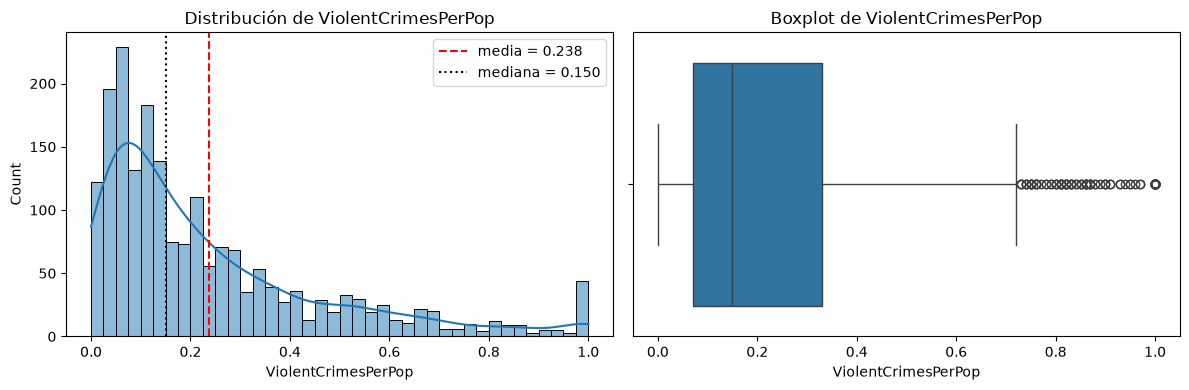

Valores atípicos (regla 1.5 IQR): 110


In [5]:
y = model.obtener_columna("ViolentCrimesPerPop")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, bins=40, kde=True, ax=ax[0])
ax[0].axvline(y.mean(), color="red", linestyle="--", label=f"media = {y.mean():.3f}")
ax[0].axvline(y.median(), color="black", linestyle=":", label=f"mediana = {y.median():.3f}")
ax[0].legend()
ax[0].set_title("Distribución de ViolentCrimesPerPop")
sns.boxplot(x=y, ax=ax[1])
ax[1].set_title("Boxplot de ViolentCrimesPerPop")
plt.tight_layout()
guardar("variable_respuesta.png")
plt.show()
print("Valores atípicos (regla 1.5 IQR):", len(model.detectar_outliers()["ViolentCrimesPerPop"]))

In [6]:
# Correlación de cada predictora con la variable a predecir (conjunto de entrenamiento)
controller.ejecutar("Correlación respuesta", top=15)


--- Datos ---


,0
PctIlleg,0.74
PctKids2Par,-0.74
PctFam2Par,-0.71
racePctWhite,-0.67
PctYoungKids2Par,-0.67
PctTeen2Par,-0.66
racepctblack,0.63
pctWInvInc,-0.57
pctWPubAsst,0.56
FemalePctDiv,0.55


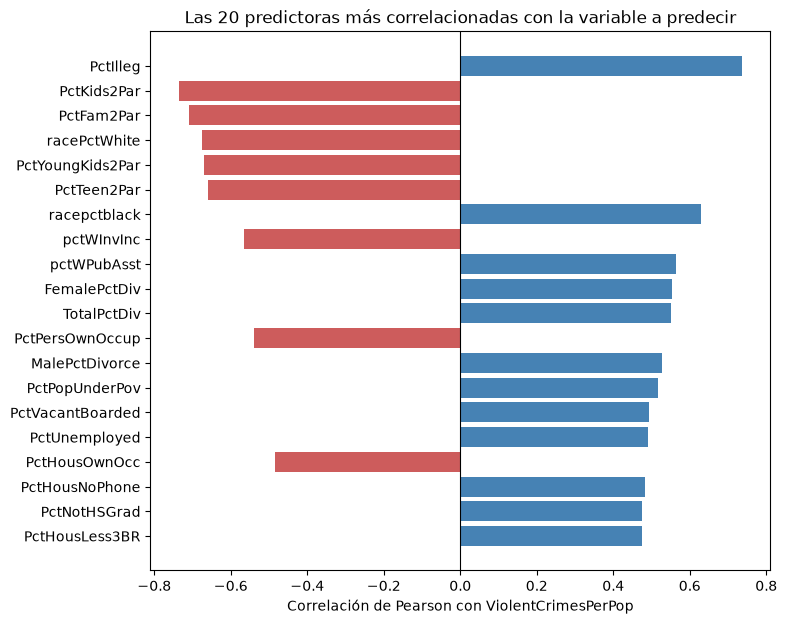

In [7]:
corr = model.correlacion_respuesta(top=20)
plt.figure(figsize=(8, 7))
plt.barh(corr.index[::-1], corr.values[::-1],
         color=["indianred" if v < 0 else "steelblue" for v in corr.values[::-1]])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlación de Pearson con ViolentCrimesPerPop")
plt.title("Las 20 predictoras más correlacionadas con la variable a predecir")
guardar("correlacion_respuesta.png")
plt.show()

Pares de predictoras con |r| > 0.9: 49
Pares de predictoras con |r| > 0.8: 127

--- Datos ---


,,|r|
PctRecImmig8,PctRecImmig10,1.00
OwnOccLowQuart,OwnOccMedVal,0.99
PctRecImmig5,PctRecImmig8,0.99
population,numbUrban,0.99
OwnOccMedVal,OwnOccHiQuart,0.99
PctRecentImmig,PctRecImmig5,0.99
RentMedian,MedRent,0.99
PctRecImmig5,PctRecImmig10,0.99
PctFam2Par,PctKids2Par,0.99
PctLargHouseFam,PctLargHouseOccup,0.98


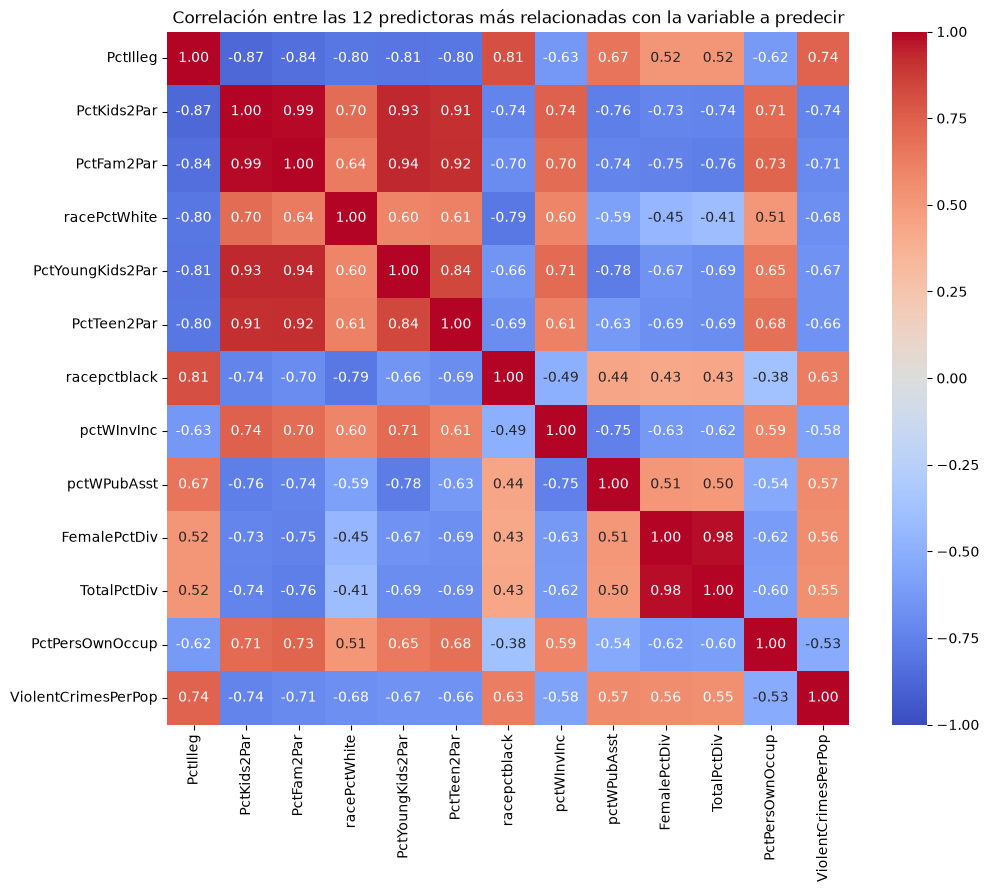

In [8]:
# Multicolinealidad: pares de predictoras con |r| > 0.9
datos = model.mostrar().drop(columns=["state", "fold", "ViolentCrimesPerPop"])
cm = datos.corr().abs()
pares = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack()
print("Pares de predictoras con |r| > 0.9:", int((pares > 0.9).sum()))
print("Pares de predictoras con |r| > 0.8:", int((pares > 0.8).sum()))
view.mostrar(pares.sort_values(ascending=False).head(10).rename("|r|").to_frame())

top = list(model.correlacion_respuesta(top=12).index) + ["ViolentCrimesPerPop"]
plt.figure(figsize=(11, 9))
sns.heatmap(model.mostrar()[top].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre las 12 predictoras más relacionadas con la variable a predecir")
guardar("mapa_calor.png")
plt.show()

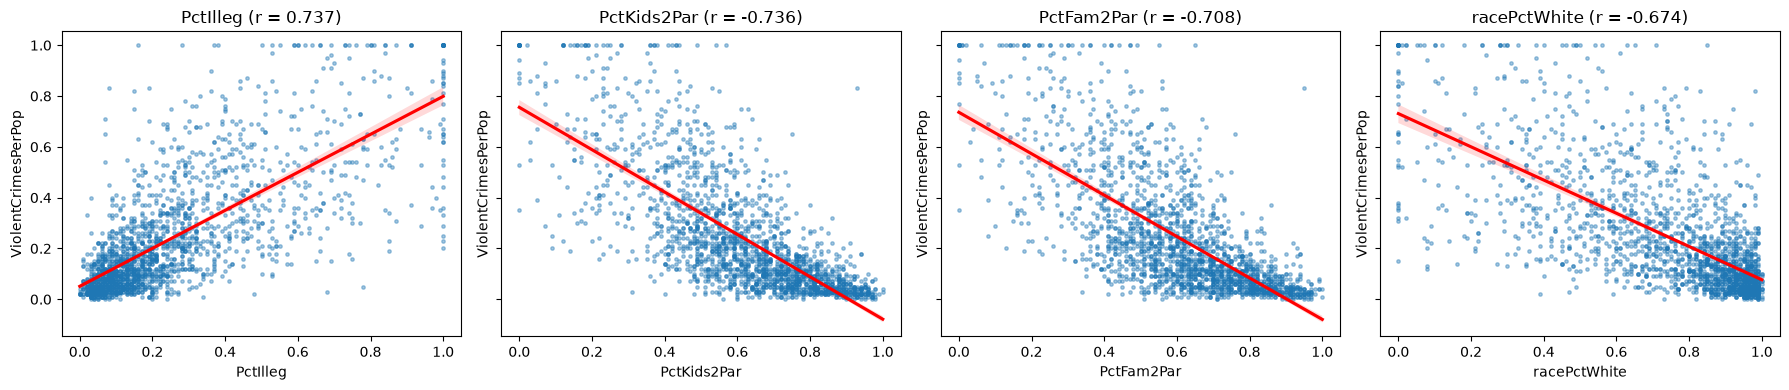

In [9]:
# Relación de las 4 predictoras más correlacionadas con la variable a predecir
top4 = list(model.correlacion_respuesta(top=4).index)
fig, ax = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for eje, col in zip(ax, top4):
    sns.regplot(data=model.mostrar(), x=col, y="ViolentCrimesPerPop", ax=eje,
                scatter_kws={"s": 6, "alpha": 0.4}, line_kws={"color": "red"})
    eje.set_title(f"{col} (r = {model.correlacion_respuesta()[col]:.3f})")
plt.tight_layout()
guardar("dispersion_top.png")
plt.show()

## Partición entrenamiento / prueba

75 % entrenamiento y 25 % prueba con semilla 42. Como la variable a predecir es continua, la partición es aleatoria simple (no estratificada). El preprocesamiento (imputación y estandarización) se hace dentro del `Pipeline`, solo con el entrenamiento.

In [10]:
controller.ejecutar("Particionar", test_size=0.25)
mejores = {}   # mejor modelo de cada algoritmo


--- Datos ---


,Conjunto,Filas,Predictoras,Media y,Desv. y,Mediana y
0,Entrenamiento,1495,100,0.24,0.24,0.16
1,Prueba,499,100,0.22,0.22,0.14


# Familia 1: modelos lineales

## Regresión lineal simple

Por defecto se usa la predictora más correlacionada con la variable a predecir en el entrenamiento. También se prueba la segunda (`PctKids2Par`), que tiene casi la misma correlación pero con signo contrario.

In [11]:
controller.ejecutar("Lineal simple")                          # PctIlleg
controller.ejecutar("Lineal simple", variable="PctKids2Par")


=== Índices de calidad ===


,RMSE,MAE,ER,R²
Lineal simple (PctIlleg),0.1490,0.1080,0.4941,0.5433



=== Índices de calidad ===


,RMSE,MAE,ER,R²
Lineal simple (PctKids2Par),0.1479,0.1067,0.4877,0.5504


RMSE    0.1479
MAE     0.1067
ER      0.4877
R²      0.5504
Name: Lineal simple (PctKids2Par), dtype: float64

PctIlleg: w0 = 0.0533, w1 = 0.7523
PctKids2Par: w0 = 0.7627, w1 = -0.8431


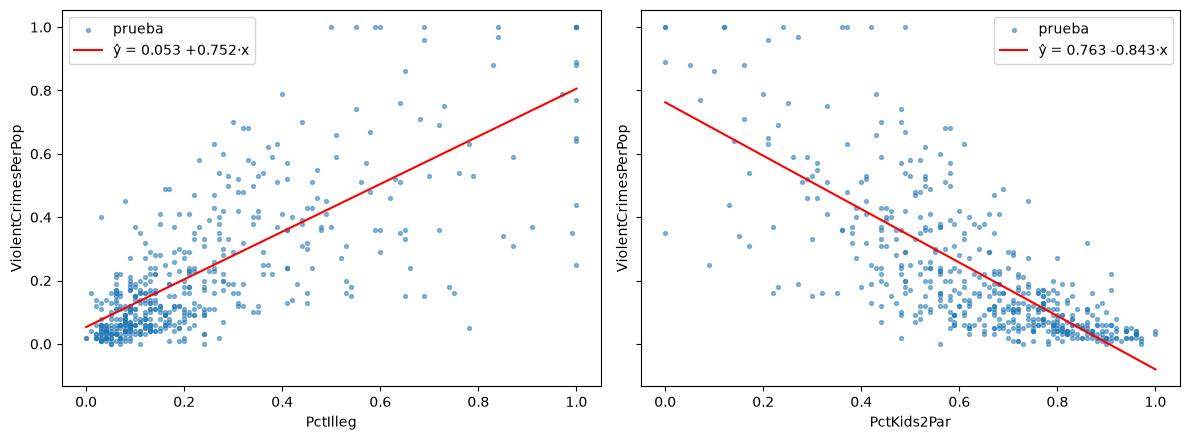


[INFO]: Mejor modelo según RMSE: Lineal simple (PctKids2Par)

=== Índices de calidad ===


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
1,Lineal simple (PctKids2Par),Lineal simple,Lineal,0.1479,0.1067,0.4877,0.5504


In [12]:
# Recta ajustada de cada modelo simple: y = w0 + w1 * x
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for eje, var in zip(ax, ["PctIlleg", "PctKids2Par"]):
    modelo = model.experimentos()[f"Lineal simple ({var})"]["pipeline"].named_steps["modelo"]
    w0, w1 = modelo.intercept_, modelo.coef_[0]
    print(f"{var}: w0 = {w0:.4f}, w1 = {w1:.4f}")
    eje.scatter(model.df.X_test[var], model.df.y_test, s=8, alpha=0.5, label="prueba")
    xs = np.linspace(0, 1, 50)
    eje.plot(xs, w0 + w1 * xs, color="red", label=f"ŷ = {w0:.3f} {w1:+.3f}·x")
    eje.set_xlabel(var)
    eje.set_ylabel("ViolentCrimesPerPop")
    eje.legend()
plt.tight_layout()
guardar("lineal_simple.png")
plt.show()
mejores["Lineal simple"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="Lineal simple")

## Regresión lineal múltiple

Mínimos cuadrados con las 100 predictoras, y con solo las 20 y 50 más relacionadas con la variable a predecir (`SelectKBest` con el estadístico F de la regresión).

In [13]:
controller.ejecutar("Comparar", algoritmo="lineal_multiple", configuraciones=[
    {},                        # estándar: mínimos cuadrados con las 100 predictoras
    {"n_atributos": 50},
    {"n_atributos": 20},
])
mejores["Lineal múltiple"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="Lineal múltiple")


=== Índices de calidad ===


,RMSE,MAE,ER,R²
Lineal múltiple (estándar),0.1301,0.0937,0.4284,0.6518
Lineal múltiple (50 atributos),0.1314,0.0922,0.4215,0.6449
Lineal múltiple (20 atributos),0.1316,0.0932,0.4263,0.6439



[INFO]: Mejor modelo según RMSE: Lineal múltiple (estándar)

=== Índices de calidad ===


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
0,Lineal múltiple (estándar),Lineal múltiple,Lineal,0.1301,0.0937,0.4284,0.6518


## Lasso (penalización L1)

Se estandariza por defecto porque la penalización depende de la escala de los coeficientes. La configuración estándar de scikit-learn usa `alpha = 1`.

In [14]:
controller.ejecutar("Comparar", algoritmo="lasso", configuraciones=[
    {},                        # estándar: alpha = 1
    {"alpha": 0.1},            # el valor del código guía del curso
    {"alpha": 0.01},
    {"alpha": 0.001},
    {"alpha": 0.001, "escalar": False},
])
mejores["Lasso"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="Lasso")


=== Índices de calidad ===


,RMSE,MAE,ER,R²
Lasso (estándar),0.2220,0.1770,0.8094,-0.0136
Lasso (alpha=0.1),0.1709,0.1330,0.6081,0.3990
Lasso (alpha=0.01),0.1297,0.0906,0.4143,0.6538
Lasso (alpha=0.001),0.1293,0.0914,0.4181,0.6563
"Lasso (alpha=0.001, sin escalar)",0.1290,0.0903,0.4127,0.6578



[INFO]: Mejor modelo según RMSE: Lasso (alpha=0.001, sin escalar)

=== Índices de calidad ===


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
4,"Lasso (alpha=0.001, sin escalar)",Lasso,Lineal,0.1290,0.0903,0.4127,0.6578


In [15]:
# LassoCV: alpha escogido con validación cruzada de 10 particiones sobre el entrenamiento
controller.ejecutar("LassoCV", cv=10)
controller.ejecutar("Parámetro óptimo")
mejores["LassoCV"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="LassoCV")


=== Índices de calidad ===


,RMSE,MAE,ER,R²
LassoCV (cv=10),0.1297,0.0921,0.4213,0.6539



--- Datos ---


,0
alpha,0.00
Coeficientes ≠ 0,62.00
Coeficientes totales,100.00



[INFO]: Mejor modelo según RMSE: LassoCV (cv=10)

=== Índices de calidad ===


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
0,LassoCV (cv=10),LassoCV,Lineal,0.1297,0.0921,0.4213,0.6539


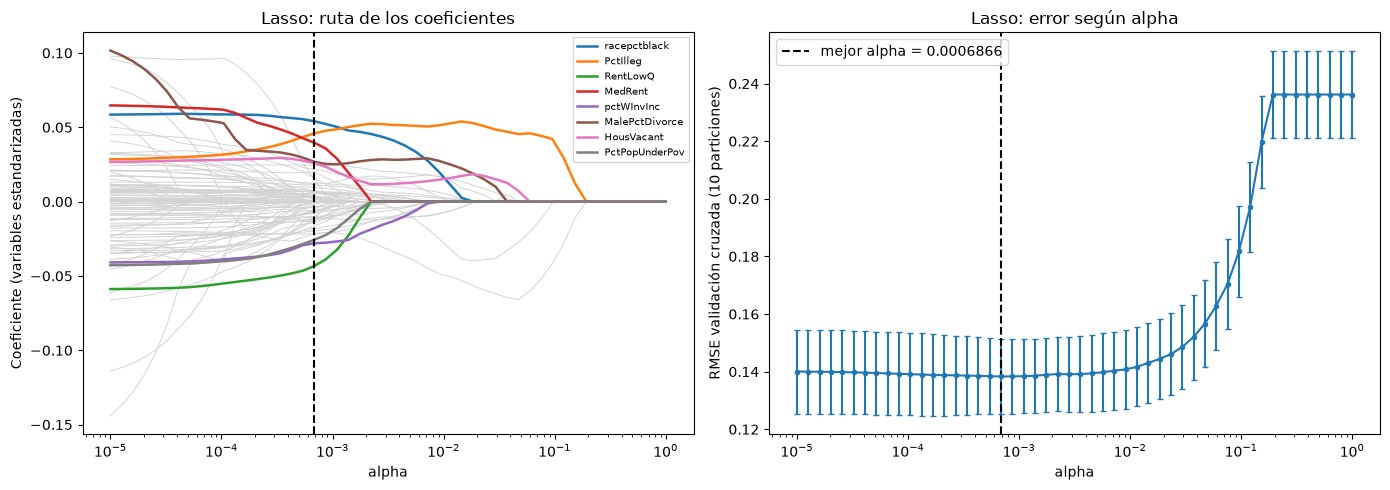


=== Índices de calidad ===


,alpha,RMSE validación,Coeficientes ≠ 0
0,0.0000,0.1400,98
7,0.0001,0.1395,91
14,0.0003,0.1387,82
21,0.0014,0.1386,41
28,0.0072,0.1403,19
35,0.0373,0.1520,6
42,0.1931,0.2362,0
49,1.0000,0.2362,0


In [16]:
# Ruta de los coeficientes y error de validación cruzada según alpha
ruta_lasso = controller.ejecutar("Ruta regularización", tipo="lasso", k=10, top=8)
guardar("lasso_ruta.png")
plt.show()
view.mostrar_indices(ruta_lasso.iloc[::7])

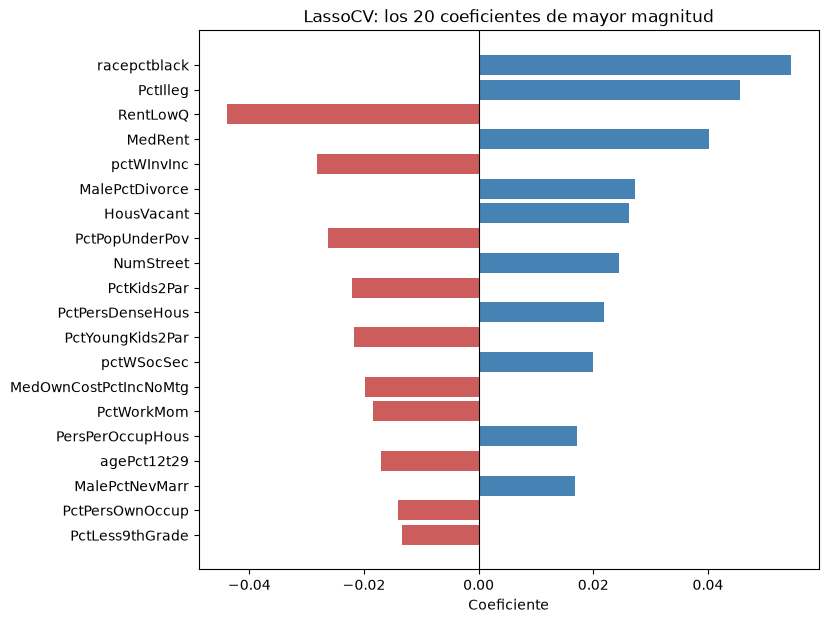

Coeficientes en cero: 38 de 100

--- Datos ---


,coeficiente
racepctblack,0.05
PctIlleg,0.05
RentLowQ,-0.04
MedRent,0.04
pctWInvInc,-0.03
MalePctDivorce,0.03
HousVacant,0.03
PctPopUnderPov,-0.03
NumStreet,0.02
PctKids2Par,-0.02


In [17]:
coef_lasso = controller.ejecutar("Coeficientes", nombre=mejores["LassoCV"], top=20,
                                 titulo="LassoCV: los 20 coeficientes de mayor magnitud")
guardar("lassocv_coeficientes.png")
plt.show()
coef_todos = model.coeficientes(mejores["LassoCV"])
print("Coeficientes en cero:", int((coef_todos == 0).sum()), "de", len(coef_todos))
view.mostrar(coef_lasso.to_frame())

## Ridge (penalización L2)

In [18]:
controller.ejecutar("Comparar", algoritmo="ridge", configuraciones=[
    {},                        # estándar: alpha = 1
    {"alpha": 10},
    {"alpha": 100},
    {"alpha": 1000},
])
mejores["Ridge"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="Ridge")


=== Índices de calidad ===


,RMSE,MAE,ER,R²
Ridge (estándar),0.1300,0.0936,0.4280,0.6525
Ridge (alpha=10),0.1298,0.0932,0.4262,0.6535
Ridge (alpha=100),0.1290,0.0915,0.4185,0.6578
Ridge (alpha=1000),0.1296,0.0913,0.4177,0.6547



[INFO]: Mejor modelo según RMSE: Ridge (alpha=100)

=== Índices de calidad ===


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
2,Ridge (alpha=100),Ridge,Lineal,0.1290,0.0915,0.4185,0.6578


In [19]:
# RidgeCV: dejando uno fuera (LOO, eficiente en Ridge) y con 10 particiones
controller.ejecutar("RidgeCV")
controller.ejecutar("Parámetro óptimo")
controller.ejecutar("RidgeCV", cv=10)
controller.ejecutar("Parámetro óptimo")
mejores["RidgeCV"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="RidgeCV")


=== Índices de calidad ===


,RMSE,MAE,ER,R²
RidgeCV (cv=LOO),0.1294,0.0923,0.4219,0.6559



--- Datos ---


,0
alpha,46.42
Coeficientes ≠ 0,100.00
Coeficientes totales,100.00



=== Índices de calidad ===


,RMSE,MAE,ER,R²
RidgeCV (cv=10),0.1292,0.0920,0.4205,0.6566



--- Datos ---


,0
alpha,64.28
Coeficientes ≠ 0,100.00
Coeficientes totales,100.00



[INFO]: Mejor modelo según RMSE: RidgeCV (cv=10)

=== Índices de calidad ===


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
1,RidgeCV (cv=10),RidgeCV,Lineal,0.1292,0.0920,0.4205,0.6566


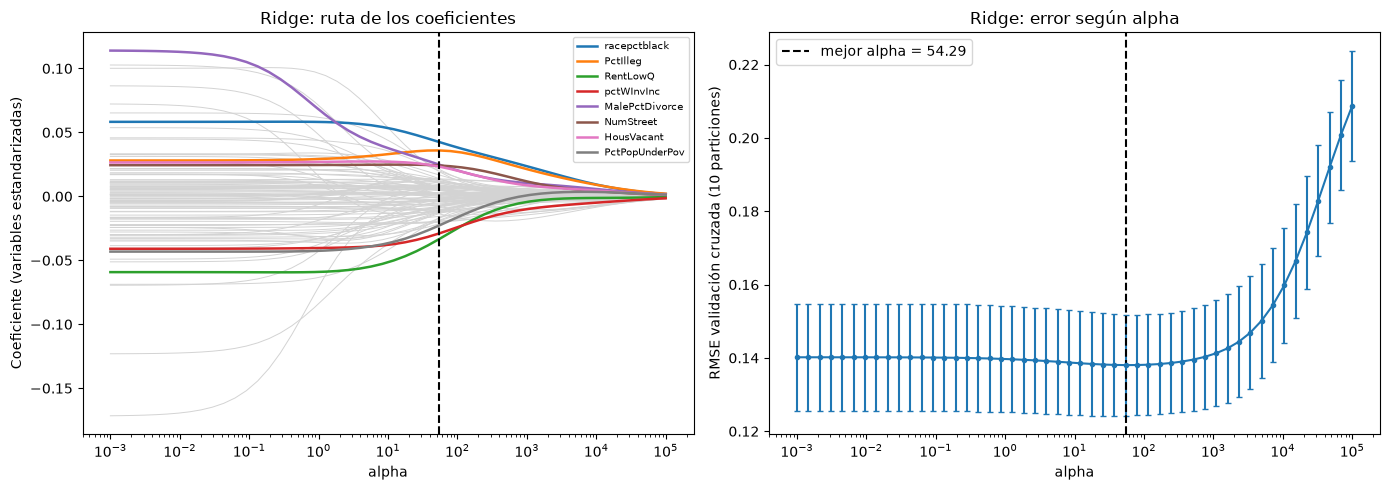


=== Índices de calidad ===


,alpha,RMSE validación,Coeficientes ≠ 0
0,0.0010,0.1402,100
7,0.0139,0.1402,100
14,0.1931,0.1400,100
21,2.6827,0.1393,100
28,37.2759,0.1381,100
35,517.9475,0.1396,100
42,7196.8567,0.1544,100
49,100000.0000,0.2088,100


In [20]:
ruta_ridge = controller.ejecutar("Ruta regularización", tipo="ridge", k=10, top=8)
guardar("ridge_ruta.png")
plt.show()
view.mostrar_indices(ruta_ridge.iloc[::7])

## Comparación dentro de la familia lineal


=== Índices de calidad ===


,Algoritmo,Familia,RMSE,MAE,ER,R²
Modelo,,,,,,
"Lasso (alpha=0.001, sin escalar)",Lasso,Lineal,0.1290,0.0903,0.4127,0.6578
Ridge (alpha=100),Ridge,Lineal,0.1290,0.0915,0.4185,0.6578
RidgeCV (cv=10),RidgeCV,Lineal,0.1292,0.0920,0.4205,0.6566
LassoCV (cv=10),LassoCV,Lineal,0.1297,0.0921,0.4213,0.6539
Lineal múltiple (estándar),Lineal múltiple,Lineal,0.1301,0.0937,0.4284,0.6518
Lineal simple (PctKids2Par),Lineal simple,Lineal,0.1479,0.1067,0.4877,0.5504


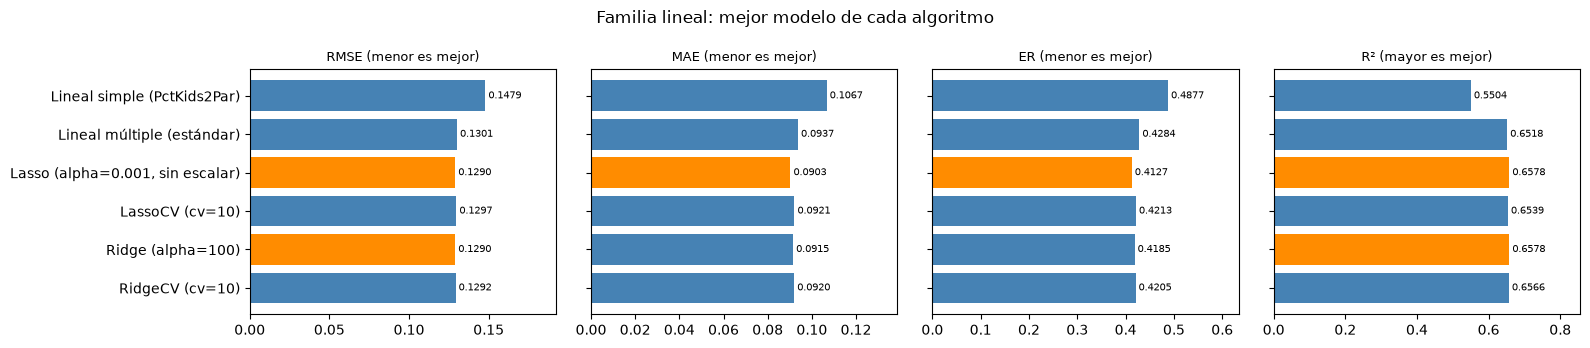

In [21]:
lineales = [mejores[a] for a in ["Lineal simple", "Lineal múltiple", "Lasso", "LassoCV", "Ridge", "RidgeCV"]]
view.mostrar_indices(model.resultados().set_index("Modelo").loc[lineales].sort_values(CRITERIO))
controller.ejecutar("Gráfico comparación", nombres=lineales, titulo="Familia lineal: mejor modelo de cada algoritmo")
guardar("comparacion_lineal.png")
plt.show()

# Familia 2: máquinas de vectores de soporte (SVR)

Se escala por defecto. La configuración estándar es kernel rbf, `C = 1`, `epsilon = 0.1` y `gamma = "scale"`. Se prueban los tres kernels del código guía (rbf, lineal y polinomial) y variaciones de `C`, `epsilon` y `gamma`.

In [22]:
# Búsqueda en rejilla del kernel rbf con validación cruzada de 5 particiones (solo entrenamiento)
controller.ejecutar("Buscar hiperparámetros", algoritmo="svr", top=8, rejilla={
    "C": [0.3, 1, 3, 10], "epsilon": [0.01, 0.05, 0.1], "gamma": [0.0005, 0.001, 0.002, 0.005, "scale"]})


=== Índices de calidad ===


,C,epsilon,gamma,RMSE validación,Desv. validación
0,1.0000,0.0500,0.0020,0.1367,0.0062
1,3.0000,0.0500,0.0010,0.1370,0.0063
2,1.0000,0.0500,0.0010,0.1376,0.0066
3,10.0000,0.0500,0.0005,0.1378,0.0066
4,0.3000,0.0500,0.0020,0.1381,0.0065
5,3.0000,0.0500,0.0005,0.1383,0.0067
6,3.0000,0.0100,0.0005,0.1385,0.0071
7,1.0000,0.1000,0.0010,0.1385,0.0061


,C,epsilon,gamma,RMSE validación,Desv. validación
0,1.0,0.05,0.002,0.1367,0.0062
1,3.0,0.05,0.001,0.1370,0.0063
2,1.0,0.05,0.001,0.1376,0.0066
3,10.0,0.05,0.0005,0.1378,0.0066
4,0.3,0.05,0.002,0.1381,0.0065
5,3.0,0.05,0.0005,0.1383,0.0067
6,3.0,0.01,0.0005,0.1385,0.0071
7,1.0,0.10,0.001,0.1385,0.0061


In [23]:
controller.ejecutar("Comparar", algoritmo="svr", configuraciones=[
    {},                                                   # estándar: rbf, C=1, epsilon=0.1
    {"C": 100},                                           # el valor del código guía
    {"epsilon": 0.01},
    {"C": 1, "epsilon": 0.05, "gamma": 0.002},             # las dos mejores de la búsqueda en rejilla
    {"C": 3, "epsilon": 0.05, "gamma": 0.001},
    {"kernel": "linear"},
    {"kernel": "linear", "C": 0.01, "epsilon": 0.01},
    {"kernel": "poly"},                                   # grado 3
    {"kernel": "poly", "degree": 2, "C": 0.1, "epsilon": 0.01},
])


=== Índices de calidad ===


,RMSE,MAE,ER,R²
SVR (estándar),0.1404,0.1024,0.4685,0.5944
SVR (C=100),0.1465,0.1072,0.4902,0.5583
SVR (epsilon=0.01),0.1354,0.0938,0.4290,0.6228
"SVR (C=1, epsilon=0.05, gamma=0.002)",0.1267,0.0853,0.3902,0.6696
"SVR (C=3, epsilon=0.05, gamma=0.001)",0.1273,0.0854,0.3907,0.6665
SVR (kernel=linear),0.1341,0.0957,0.4378,0.6301
"SVR (kernel=linear, C=0.01, epsilon=0.01)",0.1280,0.0871,0.3982,0.6631
SVR (kernel=poly),0.1600,0.1113,0.5090,0.4732
"SVR (kernel=poly, degree=2, C=0.1, epsilon=0.01)",0.1546,0.1086,0.4966,0.5086


,RMSE,MAE,ER,R²
SVR (estándar),0.1404,0.1024,0.4685,0.5944
SVR (C=100),0.1465,0.1072,0.4902,0.5583
SVR (epsilon=0.01),0.1354,0.0938,0.4290,0.6228
"SVR (C=1, epsilon=0.05, gamma=0.002)",0.1267,0.0853,0.3902,0.6696
"SVR (C=3, epsilon=0.05, gamma=0.001)",0.1273,0.0854,0.3907,0.6665
SVR (kernel=linear),0.1341,0.0957,0.4378,0.6301
"SVR (kernel=linear, C=0.01, epsilon=0.01)",0.1280,0.0871,0.3982,0.6631
SVR (kernel=poly),0.1600,0.1113,0.5090,0.4732
"SVR (kernel=poly, degree=2, C=0.1, epsilon=0.01)",0.1546,0.1086,0.4966,0.5086



=== Índices de calidad ===


,C,RMSE entrenamiento,RMSE validación,Desv. validación
0,0.0100,0.1677,0.1686,0.0058
1,0.0300,0.1496,0.1518,0.0063
2,0.1000,0.1365,0.1418,0.0068
3,0.3000,0.1282,0.1381,0.0065
4,1.0000,0.1189,0.1367,0.0062
5,3.0000,0.1073,0.1393,0.0063
6,10.0000,0.0901,0.1456,0.0075
7,30.0000,0.0702,0.1558,0.0089
8,100.0000,0.0492,0.1733,0.0116


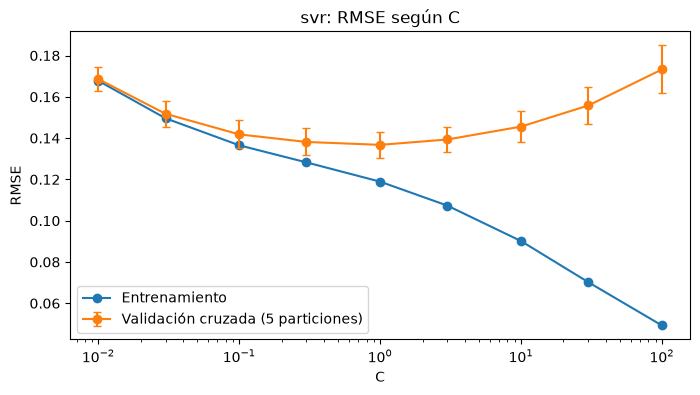

In [24]:
# RMSE de entrenamiento y validación según C (kernel rbf, gamma=0.002, epsilon=0.05)
controller.ejecutar("Curva parámetro", algoritmo="svr", parametro="C",
                    valores=[0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100], gamma=0.002, epsilon=0.05)
guardar("svr_curva_C.png")
plt.show()


[INFO]: Mejor modelo según RMSE: SVR (C=1, epsilon=0.05, gamma=0.002)

=== Índices de calidad ===


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
3,"SVR (C=1, epsilon=0.05, gamma=0.002)",SVR,Núcleos (SVR),0.1267,0.0853,0.3902,0.6696


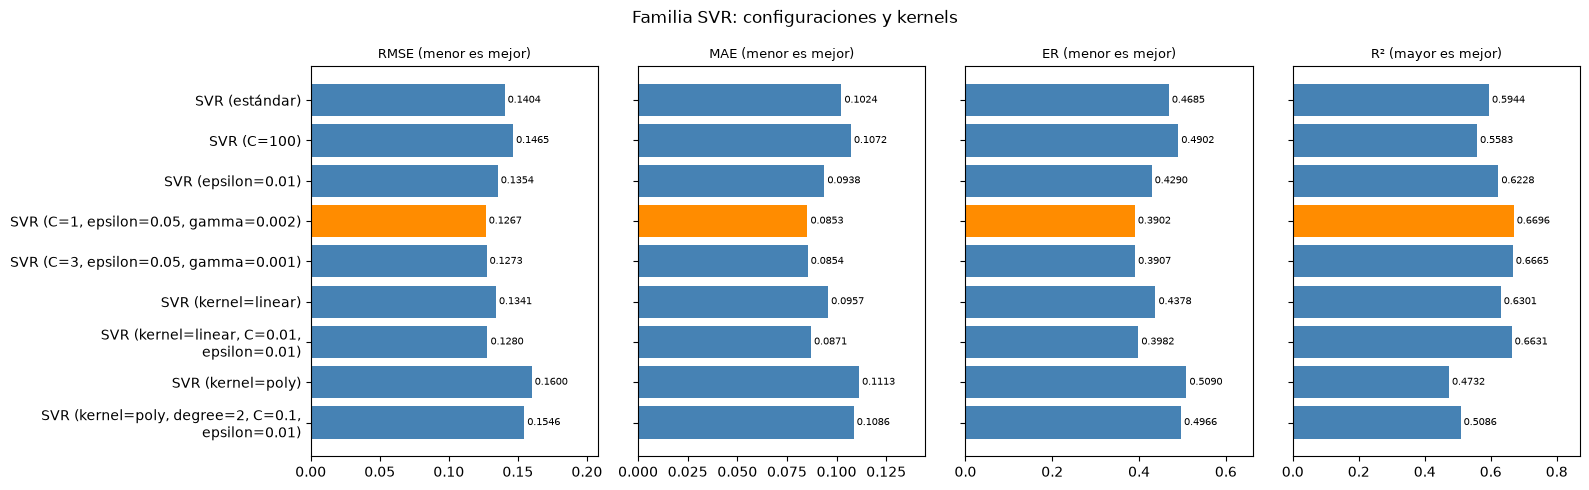

In [25]:
mejores["SVR"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="SVR")
svrs = list(model.resultados(algoritmo="SVR")["Modelo"])
controller.ejecutar("Gráfico comparación", nombres=svrs, titulo="Familia SVR: configuraciones y kernels")
guardar("comparacion_svr.png")
plt.show()

# Familia 3: árboles de decisión y ensambles

## Árbol de decisión (DT)

In [26]:
controller.ejecutar("Comparar", algoritmo="arbol", configuraciones=[
    {},                                                   # estándar: sin límite de profundidad
    {"max_depth": 3},                                     # el valor del código guía
    {"max_depth": 4},
    {"max_depth": 5, "min_samples_leaf": 20},
    {"min_samples_leaf": 30},
    {"ccp_alpha": 0.0005},                                # poda por costo-complejidad
])


=== Índices de calidad ===


,RMSE,MAE,ER,R²
DT (estándar),0.1841,0.1233,0.5641,0.3031
DT (max_depth=3),0.1468,0.1015,0.4642,0.5569
DT (max_depth=4),0.1486,0.1009,0.4612,0.5456
"DT (max_depth=5, min_samples_leaf=20)",0.1460,0.1002,0.4581,0.5614
DT (min_samples_leaf=30),0.1473,0.1018,0.4657,0.5538
DT (ccp_alpha=0.0005),0.1465,0.1027,0.4696,0.5586


,RMSE,MAE,ER,R²
DT (estándar),0.1841,0.1233,0.5641,0.3031
DT (max_depth=3),0.1468,0.1015,0.4642,0.5569
DT (max_depth=4),0.1486,0.1009,0.4612,0.5456
"DT (max_depth=5, min_samples_leaf=20)",0.1460,0.1002,0.4581,0.5614
DT (min_samples_leaf=30),0.1473,0.1018,0.4657,0.5538
DT (ccp_alpha=0.0005),0.1465,0.1027,0.4696,0.5586



=== Índices de calidad ===


,max_depth,RMSE entrenamiento,RMSE validación,Desv. validación
0,1,0.1794,0.1875,0.0125
1,2,0.1586,0.1731,0.0100
2,3,0.1461,0.1656,0.0099
3,4,0.1336,0.1635,0.0116
4,5,0.1203,0.1703,0.0142
5,6,0.1048,0.1807,0.0135
6,8,0.0752,0.1908,0.0164
7,10,0.0510,0.1968,0.0149
8,15,0.0157,0.2022,0.0145
9,20,0.0028,0.2039,0.0193


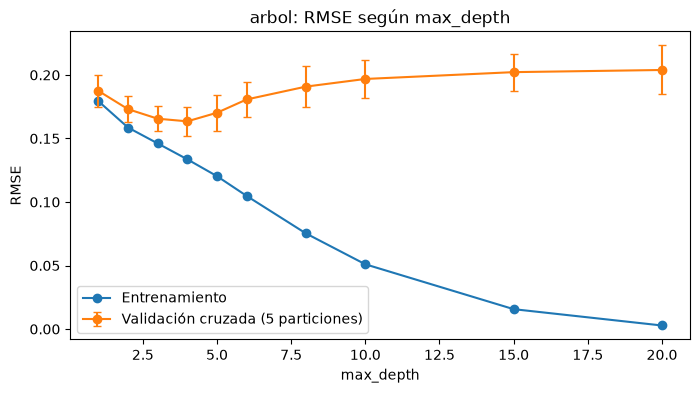

In [27]:
controller.ejecutar("Curva parámetro", algoritmo="arbol", parametro="max_depth",
                    valores=[1, 2, 3, 4, 5, 6, 8, 10, 15, 20])
guardar("dt_curva_profundidad.png")
plt.show()


[INFO]: Mejor modelo según RMSE: DT (max_depth=5, min_samples_leaf=20)

=== Índices de calidad ===


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
3,"DT (max_depth=5, min_samples_leaf=20)",DT,Árboles,0.1460,0.1002,0.4581,0.5614


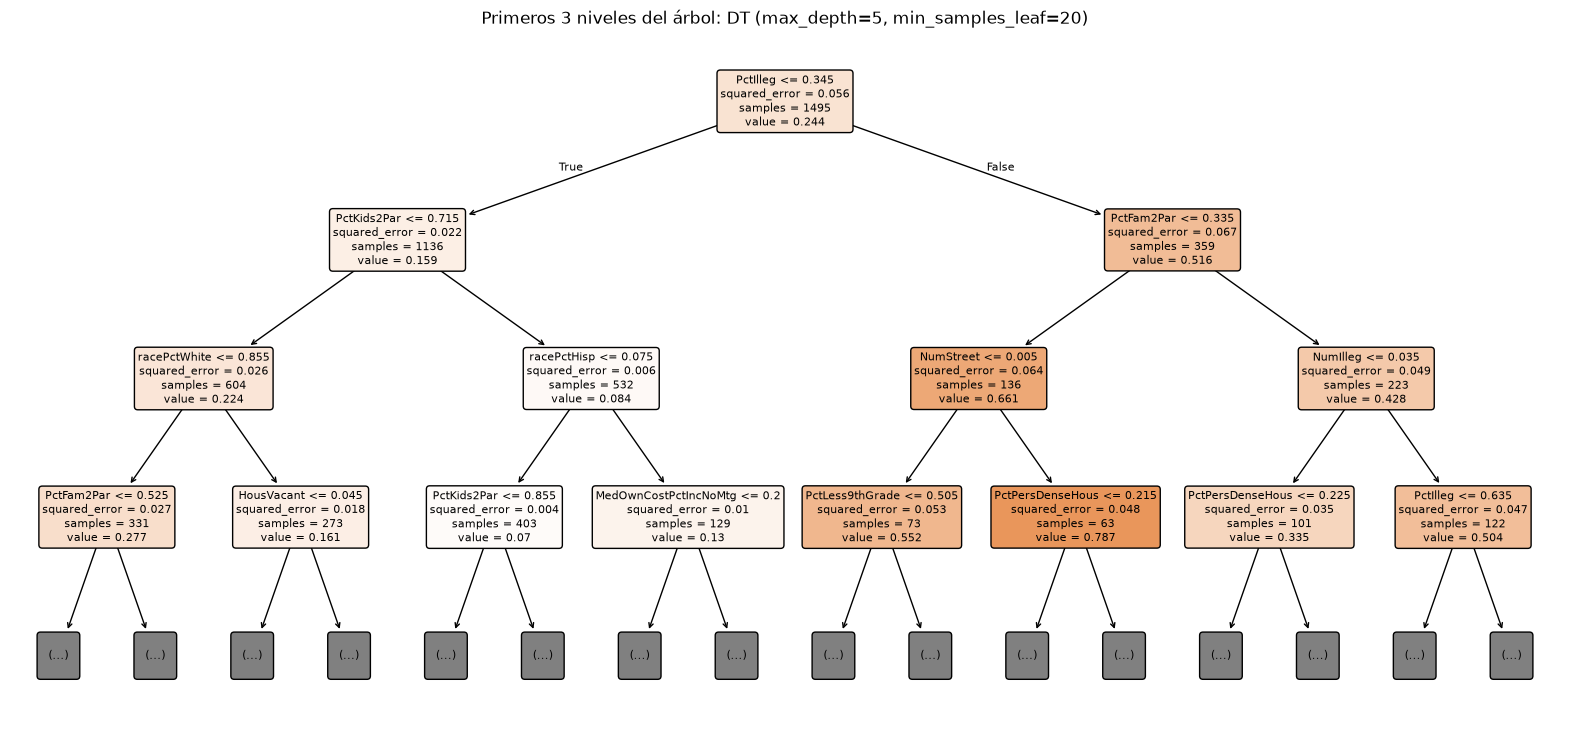

In [28]:
mejores["DT"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="DT")
controller.ejecutar("Graficar árbol", nombre=mejores["DT"], profundidad=3)
guardar("dt_arbol.png")
plt.show()

## Random Forest (RF)

In [29]:
controller.ejecutar("Comparar", algoritmo="bosque", configuraciones=[
    {},                                                   # estándar: 100 árboles, todas las variables
    {"max_depth": 2},                                     # el valor del código guía
    {"n_estimators": 500},
    {"n_estimators": 500, "max_features": 0.33},          # p/3 variables por división
    {"n_estimators": 500, "max_features": 0.33, "min_samples_leaf": 5},
])
mejores["RF"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="RF")


=== Índices de calidad ===


,RMSE,MAE,ER,R²
RF (estándar),0.1314,0.0921,0.4214,0.6451
RF (max_depth=2),0.1436,0.1036,0.4738,0.5759
RF (n_estimators=500),0.1317,0.0918,0.4198,0.6435
"RF (n_estimators=500, max_features=0.33)",0.1300,0.0910,0.4162,0.6522
"RF (n_estimators=500, max_features=0.33, min_samples_leaf=5)",0.1292,0.0887,0.4058,0.6568



[INFO]: Mejor modelo según RMSE: RF (n_estimators=500, max_features=0.33, min_samples_leaf=5)

=== Índices de calidad ===


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
4,"RF (n_estimators=500, max_features=0.33, min_samples_leaf=5)",RF,Árboles,0.1292,0.0887,0.4058,0.6568


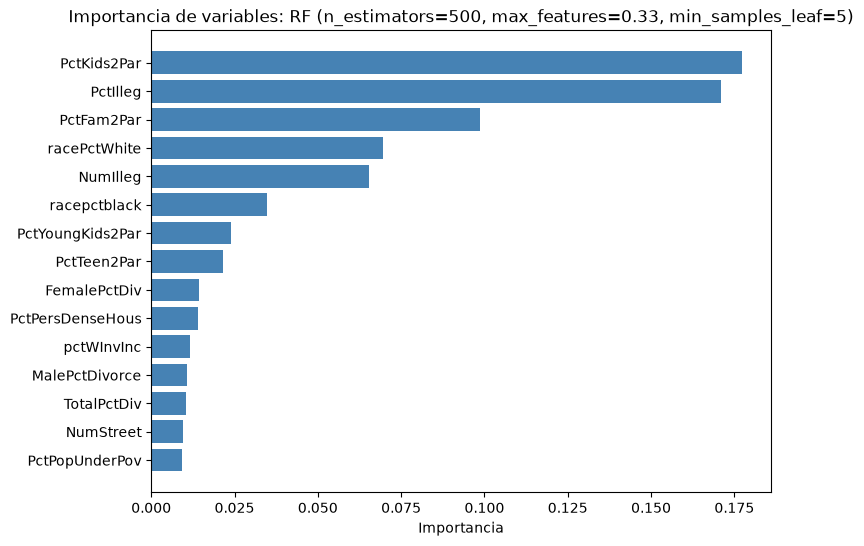

In [30]:
controller.ejecutar("Importancia", nombre=mejores["RF"])
guardar("rf_importancia.png")
plt.show()

## XGBoost (potenciación)

No es uno de los algoritmos obligatorios, pero se incluye porque el código guía usa potenciación (`GradientBoostingRegressor`) y el framework ya tenía XGBoost del Laboratorio 02.

In [31]:
controller.ejecutar("Comparar", algoritmo="xgboost", configuraciones=[
    {},                                                   # estándar: 100 árboles, lr=0.3, profundidad 6
    {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 3},
    {"n_estimators": 500, "learning_rate": 0.02, "max_depth": 3, "subsample": 0.8, "colsample_bytree": 0.5},
    {"n_estimators": 500, "learning_rate": 0.02, "max_depth": 2, "subsample": 0.8, "colsample_bytree": 0.5,
     "min_child_weight": 5},
])
mejores["XGBoost"] = controller.ejecutar("Mejor modelo", criterio=CRITERIO, algoritmo="XGBoost")


=== Índices de calidad ===


,RMSE,MAE,ER,R²
XGBoost (estándar),0.1379,0.0935,0.4275,0.6087
"XGBoost (n_estimators=300, learning_rate=0.05, max_depth=3)",0.1331,0.0884,0.4042,0.6359
"XGBoost (n_estimators=500, learning_rate=0.02, max_depth=3, subsample=0.8, colsample_bytree=0.5)",0.1299,0.0875,0.4002,0.6530
"XGBoost (n_estimators=500, learning_rate=0.02, max_depth=2, subsample=0.8, colsample_bytree=0.5, min_child_weight=5)",0.1303,0.0881,0.4031,0.6511



[INFO]: Mejor modelo según RMSE: XGBoost (n_estimators=500, learning_rate=0.02, max_depth=3, subsample=0.8, colsample_bytree=0.5)

=== Índices de calidad ===


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
2,"XGBoost (n_estimators=500, learning_rate=0.02, max_depth=3, subsample=0.8, colsample_bytree=0.5)",XGBoost,Árboles,0.1299,0.0875,0.4002,0.6530


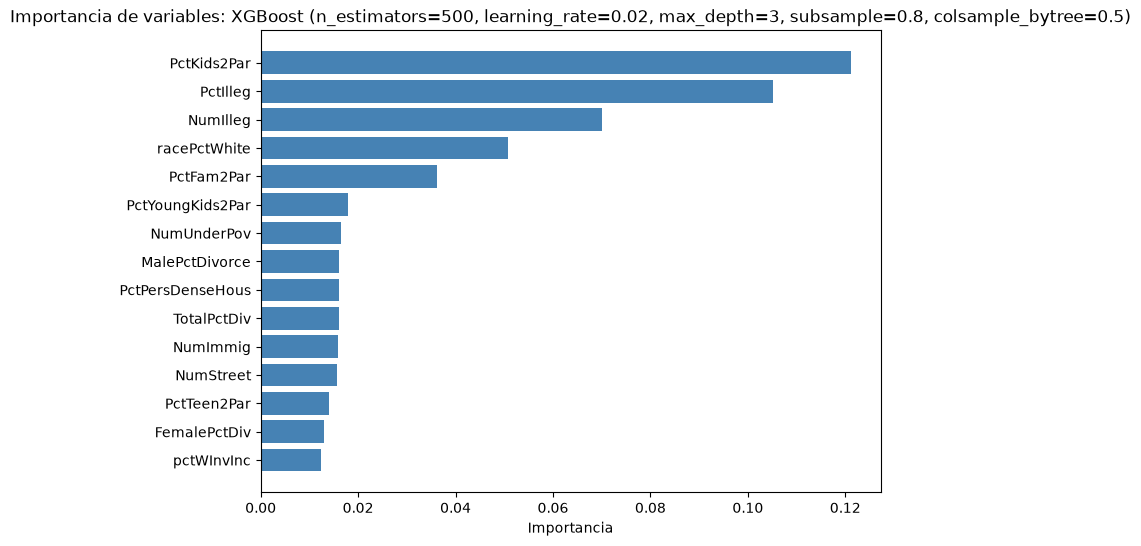

In [32]:
controller.ejecutar("Importancia", nombre=mejores["XGBoost"])
guardar("xgboost_importancia.png")
plt.show()

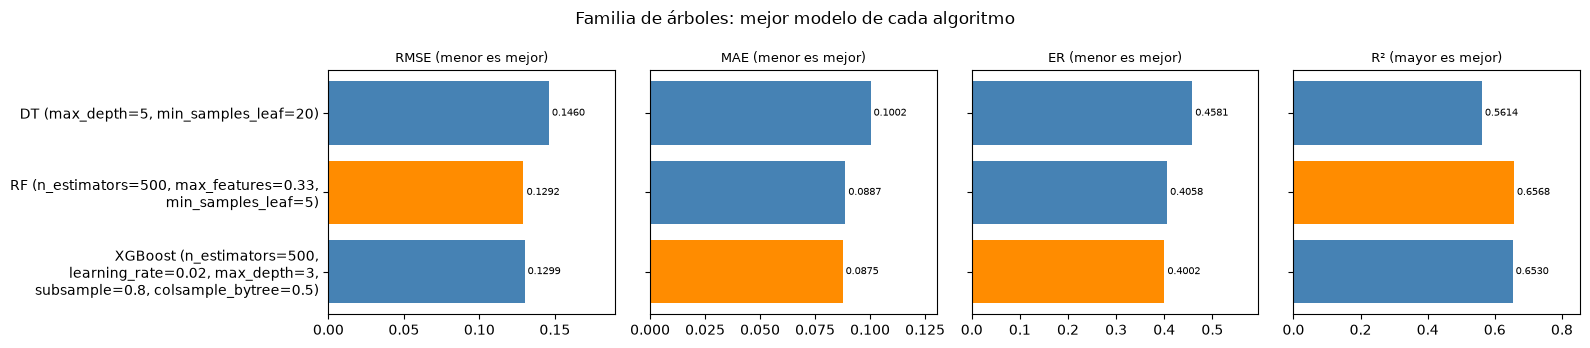

In [33]:
arboles = [mejores[a] for a in ["DT", "RF", "XGBoost"]]
controller.ejecutar("Gráfico comparación", nombres=arboles, titulo="Familia de árboles: mejor modelo de cada algoritmo")
guardar("comparacion_arboles.png")
plt.show()

# Comparación entre familias

In [34]:
controller.ejecutar("Resultados")


=== Índices de calidad ===


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
0,Lineal simple (PctIlleg),Lineal simple,Lineal,0.1490,0.1080,0.4941,0.5433
1,Lineal simple (PctKids2Par),Lineal simple,Lineal,0.1479,0.1067,0.4877,0.5504
2,Lineal múltiple (estándar),Lineal múltiple,Lineal,0.1301,0.0937,0.4284,0.6518
3,Lineal múltiple (50 atributos),Lineal múltiple,Lineal,0.1314,0.0922,0.4215,0.6449
4,Lineal múltiple (20 atributos),Lineal múltiple,Lineal,0.1316,0.0932,0.4263,0.6439
5,Lasso (estándar),Lasso,Lineal,0.2220,0.1770,0.8094,-0.0136
6,Lasso (alpha=0.1),Lasso,Lineal,0.1709,0.1330,0.6081,0.3990
7,Lasso (alpha=0.01),Lasso,Lineal,0.1297,0.0906,0.4143,0.6538
8,Lasso (alpha=0.001),Lasso,Lineal,0.1293,0.0914,0.4181,0.6563
9,"Lasso (alpha=0.001, sin escalar)",Lasso,Lineal,0.1290,0.0903,0.4127,0.6578


In [35]:
# Mejor modelo de cada algoritmo y de cada familia (en el conjunto de prueba)
tabla = model.resultados().set_index("Modelo").loc[list(mejores.values())]
view.mostrar_indices(tabla.sort_values(CRITERIO))
controller.ejecutar("Mejores", criterio=CRITERIO, por="Familia")


=== Índices de calidad ===


,Algoritmo,Familia,RMSE,MAE,ER,R²
Modelo,,,,,,
"SVR (C=1, epsilon=0.05, gamma=0.002)",SVR,Núcleos (SVR),0.1267,0.0853,0.3902,0.6696
"Lasso (alpha=0.001, sin escalar)",Lasso,Lineal,0.1290,0.0903,0.4127,0.6578
Ridge (alpha=100),Ridge,Lineal,0.1290,0.0915,0.4185,0.6578
RidgeCV (cv=10),RidgeCV,Lineal,0.1292,0.0920,0.4205,0.6566
"RF (n_estimators=500, max_features=0.33, min_samples_leaf=5)",RF,Árboles,0.1292,0.0887,0.4058,0.6568
LassoCV (cv=10),LassoCV,Lineal,0.1297,0.0921,0.4213,0.6539
"XGBoost (n_estimators=500, learning_rate=0.02, max_depth=3, subsample=0.8, colsample_bytree=0.5)",XGBoost,Árboles,0.1299,0.0875,0.4002,0.6530
Lineal múltiple (estándar),Lineal múltiple,Lineal,0.1301,0.0937,0.4284,0.6518
"DT (max_depth=5, min_samples_leaf=20)",DT,Árboles,0.1460,0.1002,0.4581,0.5614



=== Índices de calidad ===


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
0,"SVR (C=1, epsilon=0.05, gamma=0.002)",SVR,Núcleos (SVR),0.1267,0.0853,0.3902,0.6696
1,Ridge (alpha=100),Ridge,Lineal,0.1290,0.0915,0.4185,0.6578
2,"RF (n_estimators=500, max_features=0.33, min_samples_leaf=5)",RF,Árboles,0.1292,0.0887,0.4058,0.6568


,Modelo,Algoritmo,Familia,RMSE,MAE,ER,R²
0,"SVR (C=1, epsilon=0.05, gamma=0.002)",SVR,Núcleos (SVR),0.1267,0.0853,0.3902,0.6696
1,Ridge (alpha=100),Ridge,Lineal,0.1290,0.0915,0.4185,0.6578
2,"RF (n_estimators=500, max_features=0.33, min_s...",RF,Árboles,0.1292,0.0887,0.4058,0.6568


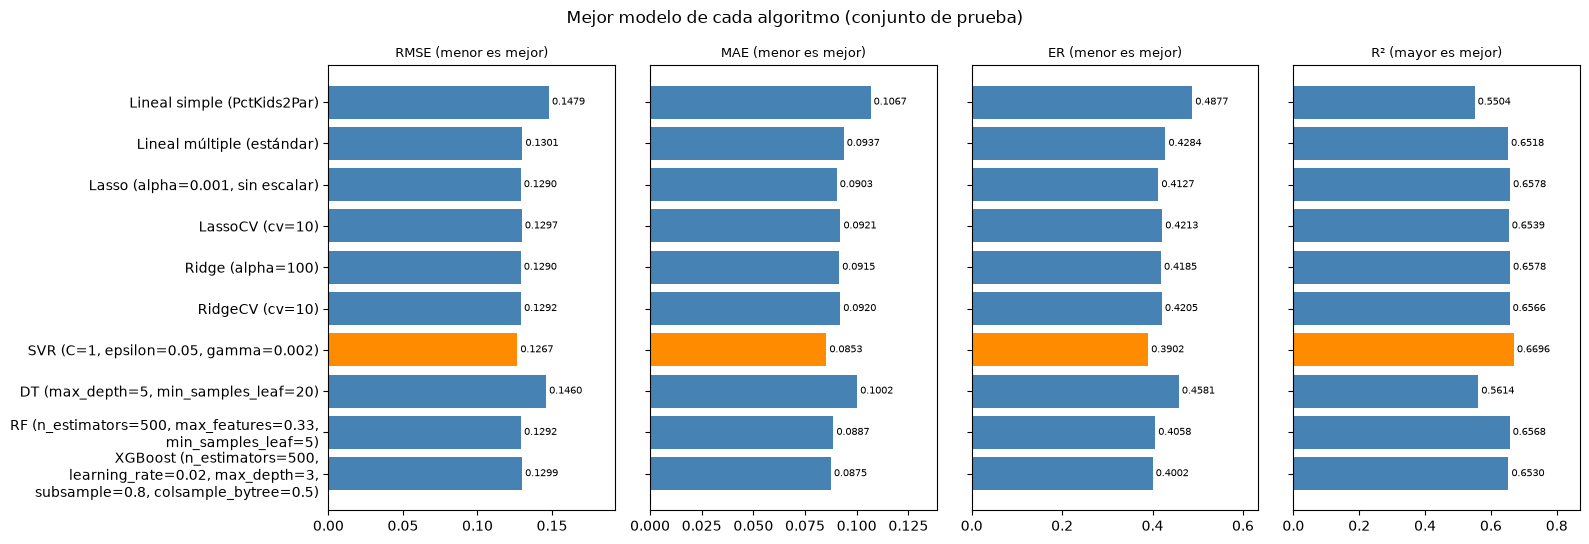

In [36]:
controller.ejecutar("Gráfico comparación", nombres=list(mejores.values()),
                    titulo="Mejor modelo de cada algoritmo (conjunto de prueba)")
guardar("comparacion_mejores.png")
plt.show()

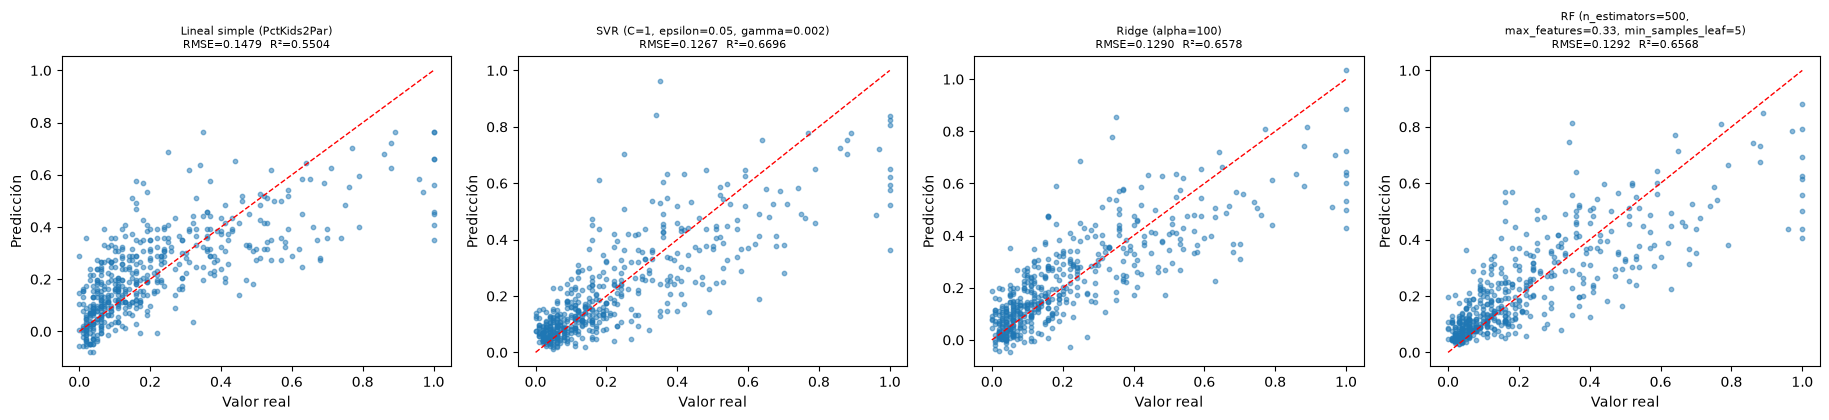

In [37]:
# Valores reales contra predicciones: modelo simple y mejor modelo de cada familia
familias = model.mejores(CRITERIO, por="Familia")["Modelo"].tolist()
controller.ejecutar("Real vs predicho", nombres=[mejores["Lineal simple"]] + familias, columnas=4)
guardar("real_vs_predicho.png")
plt.show()

Mejor modelo en prueba: SVR (C=1, epsilon=0.05, gamma=0.002)


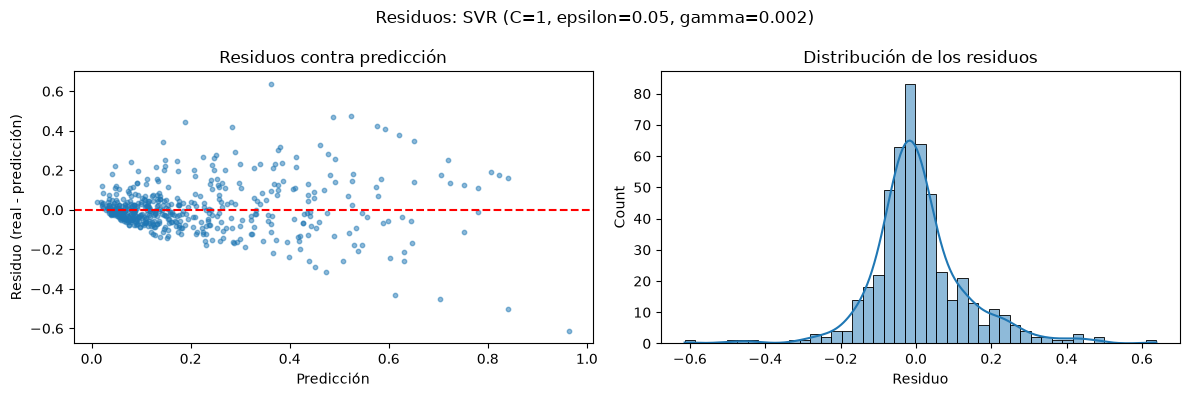

Correlación residuo - valor real: 0.5855
Error medio en comunidades con ViolentCrimesPerPop > 0.5: 0.1889


In [38]:
mejor_global = model.mejor_modelo(CRITERIO)["Modelo"]
print("Mejor modelo en prueba:", mejor_global)
controller.ejecutar("Residuos", nombre=mejor_global)
guardar("residuos.png")
plt.show()
r = model.residuos(mejor_global)
print("Correlación residuo - valor real:", round(r["Residuo"].corr(r["Real"]), 4))
print("Error medio en comunidades con ViolentCrimesPerPop > 0.5:", round(r.loc[r["Real"] > 0.5, "Residuo"].mean(), 4))

# Benchmarking: validación cruzada repetida

Un solo conjunto de prueba puede favorecer a un modelo por azar. Por eso el mejor modelo de cada algoritmo se evalúa con validación cruzada de 10 particiones repetida 3 veces (30 particiones) sobre el entrenamiento, **con las mismas particiones para todos los modelos**. Luego se aplica la prueba de Friedman y la de Wilcoxon (mejor modelo contra cada uno de los demás, con corrección de Holm).

In [39]:
bench = controller.ejecutar("Benchmark", nombres=list(mejores.values()), k=10, repeticiones=3)


=== Índices de calidad ===


,Modelo,Familia,RMSE promedio,RMSE desv.,MAE promedio,MAE desv.,R² promedio,R² desv.,Rango promedio
0,"SVR (C=1, epsilon=0.05, gamma=0.002)",Núcleos (SVR),0.1345,0.0146,0.0906,0.0072,0.6713,0.0544,2.3667
1,"XGBoost (n_estimators=500, learning_rate=0.02, max_depth=3, subsample=0.8, colsample_bytree=0.5)",Árboles,0.1367,0.0136,0.0931,0.0072,0.6600,0.0583,3.5667
2,"RF (n_estimators=500, max_features=0.33, min_samples_leaf=5)",Árboles,0.1371,0.0136,0.0946,0.0076,0.6580,0.0571,3.6000
3,Ridge (alpha=100),Lineal,0.1384,0.0129,0.0970,0.0076,0.6515,0.0564,4.3333
4,RidgeCV (cv=10),Lineal,0.1384,0.0129,0.0971,0.0075,0.6513,0.0565,4.3333
5,LassoCV (cv=10),Lineal,0.1390,0.0127,0.0976,0.0074,0.6482,0.0563,5.2333
6,"Lasso (alpha=0.001, sin escalar)",Lineal,0.1400,0.0127,0.0975,0.0074,0.6433,0.0548,6.2000
7,Lineal múltiple (estándar),Lineal,0.1403,0.0135,0.1001,0.0075,0.6412,0.0601,6.6000
8,"DT (max_depth=5, min_samples_leaf=20)",Árboles,0.1583,0.0140,0.1077,0.0090,0.5425,0.0809,9.2000
9,Lineal simple (PctKids2Par),Lineal,0.1599,0.0114,0.1171,0.0073,0.5350,0.0570,9.5667


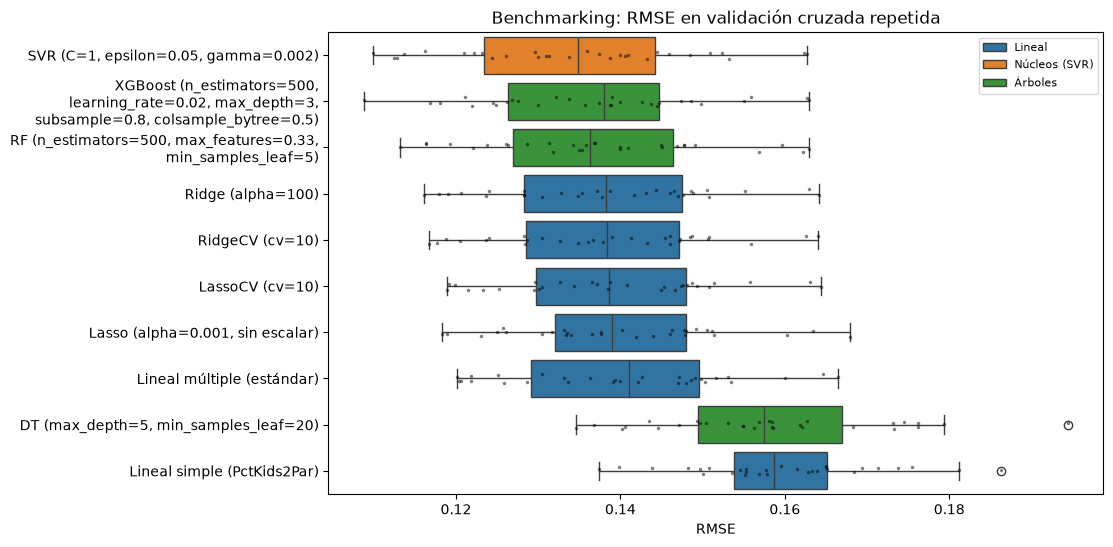

In [40]:
controller.ejecutar("Gráfico benchmark", criterio="RMSE")
guardar("benchmark_rmse.png")
plt.show()

In [41]:
friedman, comparaciones = controller.ejecutar("Prueba estadística", criterio="RMSE")


--- Datos ---


,Friedman
Chi² de Friedman,169.81
p,0.00
Modelos,10.00
Particiones,30.00



--- Datos ---


,Mejor,Contra,Diferencia RMSE,p,p Holm,Significativa
0,"SVR (C=1, epsilon=0.05, gamma=0.002)",Lineal simple (PctKids2Par),0.03,0.00,0.00,sí
1,"SVR (C=1, epsilon=0.05, gamma=0.002)","DT (max_depth=5, min_samples_leaf=20)",0.02,0.00,0.00,sí
2,"SVR (C=1, epsilon=0.05, gamma=0.002)",Lineal múltiple (estándar),0.01,0.00,0.00,sí
3,"SVR (C=1, epsilon=0.05, gamma=0.002)","Lasso (alpha=0.001, sin escalar)",0.01,0.00,0.00,sí
4,"SVR (C=1, epsilon=0.05, gamma=0.002)",LassoCV (cv=10),0.00,0.00,0.00,sí
5,"SVR (C=1, epsilon=0.05, gamma=0.002)",Ridge (alpha=100),0.00,0.00,0.00,sí
6,"SVR (C=1, epsilon=0.05, gamma=0.002)",RidgeCV (cv=10),0.00,0.00,0.00,sí
7,"SVR (C=1, epsilon=0.05, gamma=0.002)","RF (n_estimators=500, max_features=0.33, min_samples_leaf=5)",0.00,0.01,0.02,sí
8,"SVR (C=1, epsilon=0.05, gamma=0.002)","XGBoost (n_estimators=500, learning_rate=0.02, max_depth=3, subsample=0.8, colsample_bytree=0.5)",0.00,0.06,0.06,no


In [42]:
# Benchmarking entre familias: mejor modelo de cada familia según el RMSE promedio de la validación cruzada
resumen = model.resumen_benchmark()
view.mostrar_indices(resumen.sort_values("RMSE promedio").groupby("Familia", sort=False).head(1))


=== Índices de calidad ===


,Modelo,Familia,RMSE promedio,RMSE desv.,MAE promedio,MAE desv.,R² promedio,R² desv.,Rango promedio
0,"SVR (C=1, epsilon=0.05, gamma=0.002)",Núcleos (SVR),0.1345,0.0146,0.0906,0.0072,0.6713,0.0544,2.3667
1,"XGBoost (n_estimators=500, learning_rate=0.02, max_depth=3, subsample=0.8, colsample_bytree=0.5)",Árboles,0.1367,0.0136,0.0931,0.0072,0.6600,0.0583,3.5667
3,Ridge (alpha=100),Lineal,0.1384,0.0129,0.0970,0.0076,0.6515,0.0564,4.3333


In [43]:
# Se guardan los índices de todos los experimentos y del benchmarking
model.resultados().to_csv(f"{CARPETA}/resultados.csv", index=False)
bench.to_csv(f"{CARPETA}/benchmark.csv", index=False)
resumen.to_csv(f"{CARPETA}/resumen_benchmark.csv", index=False)
comparaciones.to_csv(f"{CARPETA}/wilcoxon.csv", index=False)